### **Elliptic Curve Cryptography**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jrafa1607/Cryptography_In_Python/blob/main/Algorithms/Elliptic_Curve_Cryptography.ipynb)

> **Elliptic curve cryptography (ECC)** works with points on a curve `y² = x³ + ax + b` over a **finite field** (integers modulo a prime). Points can be added, and multiplying a point by a large integer is easy while reversing it (the elliptic-curve discrete logarithm) is hard. ECC gives the same security as RSA with much smaller keys: 256-bit ECC ≈ 3072-bit RSA. This notebook implements the arithmetic, runs ECDH on a toy curve, validates the real **secp256k1** parameters, and finishes with ECDSA signatures.

> [!WARNING]
> Educational code. Never use these implementations to protect real data: use a vetted library (for example, `cryptography`) with modern, authenticated algorithms.

#### **01. Point Arithmetic over a Finite Field**

Cryptographic curves use arithmetic **modulo a prime**, not real numbers: divisions become multiplications by a modular inverse, and every coordinate stays an exact integer (floating-point coordinates lose precision immediately). A special **point at infinity** (`None` here) is the identity element.

Points on y^2 = x^3 + 2x + 2 (mod 17): 18 + infinity
G = (5, 1) has order 19: (5, 1), (6, 3), (10, 6), (3, 1), (9, 16), (16, 13), (0, 6), (13, 7), (7, 6), (7, 11), (13, 10), (0, 11), (16, 4), (9, 1), (3, 16), (10, 11), (6, 14), (5, 16), None


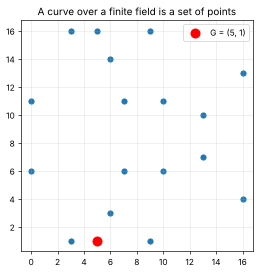

In [1]:
# Curve arithmetic modulo p, with the point at infinity represented as None
import secrets

from matplotlib import pyplot as plt

class Curve:
    def __init__(self, a, b, p):
        self.a, self.b, self.p = a, b, p
        assert (4 * a ** 3 + 27 * b ** 2) % p != 0, "singular curve"

    def contains(self, P):
        return P is None or (P[1] ** 2 - P[0] ** 3 - self.a * P[0] - self.b) % self.p == 0

    def add(self, P, Q):
        if P is None: return Q
        if Q is None: return P
        (x1, y1), (x2, y2) = P, Q
        if x1 == x2 and (y1 + y2) % self.p == 0:
            return None                                              # P + (-P) = infinity
        if P == Q:
            m = (3 * x1 * x1 + self.a) * pow(2 * y1, -1, self.p)     # tangent slope
        else:
            m = (y2 - y1) * pow(x2 - x1, -1, self.p)                 # chord slope
        x3 = (m * m - x1 - x2) % self.p
        return x3, (m * (x1 - x3) - y1) % self.p

    def multiply(self, k, P):
        """Double-and-add: about log2(k) doublings."""
        result, addend = None, P
        while k:
            if k & 1:
                result = self.add(result, addend)
            addend = self.add(addend, addend)
            k >>= 1
        return result

toy = Curve(a=2, b=2, p=17)
points = [(x, y) for x in range(17) for y in range(17) if toy.contains((x, y))]
G = (5, 1)
multiples = [toy.multiply(k, G) for k in range(1, 21)]
order = multiples.index(None) + 1
print(f"Points on y^2 = x^3 + 2x + 2 (mod 17): {len(points)} + infinity")
print(f"G = {G} has order {order}: " + ", ".join(str(P) for P in multiples[:order]))

plt.figure(figsize=(5, 5))
plt.scatter(*zip(*points), s=40)
plt.scatter(*G, s=120, c="red", label="G = (5, 1)")
plt.title("A curve over a finite field is a set of points"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

#### **02. ECDH on the Toy Curve**

Alice and Bob pick secret integers, publish `a·G` and `b·G`, and both compute `a·b·G`. With 19 possible points, an attacker just tries them all; on real curves the group has about 2^256 points.

In [2]:
# Elliptic-curve Diffie-Hellman with tiny numbers
a = secrets.randbelow(order - 1) + 1
b = secrets.randbelow(order - 1) + 1
A, B = toy.multiply(a, G), toy.multiply(b, G)
alice, bob = toy.multiply(a, B), toy.multiply(b, A)
print(f"Alice: secret {a}, public {A} | Bob: secret {b}, public {B}")
print(f"Shared point: {alice} = {bob}")
assert alice == bob

stolen = next(k for k in range(1, order) if toy.multiply(k, G) == A)   # brute force: trivial here
print(f"Brute force finds Alice's secret in at most {order} tries: {stolen}")

Alice: secret 3, public (10, 6) | Bob: secret 2, public (6, 3)
Shared point: (16, 13) = (16, 13)
Brute force finds Alice's secret in at most 19 tries: 3


#### **03. A Real Curve: secp256k1**

The same code works on **secp256k1** (used by Bitcoin and Ethereum). The checks below confirm that the generator lies on the curve and that multiplying it by the group order `n` returns the point at infinity.

In [3]:
# Validate the published secp256k1 parameters with the code above
P256K1 = 2 ** 256 - 2 ** 32 - 977
secp256k1 = Curve(a=0, b=7, p=P256K1)
G256 = (0x79BE667EF9DCBBAC55A06295CE870B07029BFCDB2DCE28D959F2815B16F81798,
        0x483ADA7726A3C4655DA4FBFC0E1108A8FD17B448A68554199C47D08FFB10D4B8)
N256 = 0xFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFEBAAEDCE6AF48A03BBFD25E8CD0364141

private = secrets.randbelow(N256 - 1) + 1
public = secp256k1.multiply(private, G256)
print("G is on the curve       :", secp256k1.contains(G256))
print("n · G = infinity         :", secp256k1.multiply(N256, G256) is None)
print("Public key is on curve   :", secp256k1.contains(public))
print(f"Public key x = {public[0]:064x}")

G is on the curve       : True
n · G = infinity         : True
Public key is on curve   : True
Public key x = 8cc9001c32be6dae83369f6c8be91b24e6dcd7e3f7c616f64ddd1e7c93180d99


#### **04. ECDSA with a Vetted Library**

For real use, rely on a library that implements constant-time arithmetic and safe nonce generation (a repeated ECDSA nonce reveals the private key, as in the 2010 PlayStation 3 key leak).

In [4]:
# ECDSA signatures on P-256 with the cryptography library
from cryptography.exceptions import InvalidSignature
from cryptography.hazmat.primitives import hashes
from cryptography.hazmat.primitives.asymmetric import ec

signing_key = ec.generate_private_key(ec.SECP256R1())
message = b"Release v2.0.0 approved by security"
signature = signing_key.sign(message, ec.ECDSA(hashes.SHA256()))
signing_key.public_key().verify(signature, message, ec.ECDSA(hashes.SHA256()))
print(f"Signature ({len(signature)} bytes) valid")
try:
    signing_key.public_key().verify(signature, b"Release v2.0.1 approved by security", ec.ECDSA(hashes.SHA256()))
except InvalidSignature:
    print("Signature rejected for a modified message")

Signature (70 bytes) valid
Signature rejected for a modified message


#### **Key Takeaways**

* Curve arithmetic must use a finite field; real-number versions are only illustrations.
* Scalar multiplication (double-and-add) is fast; reversing it is the hard problem behind ECDH and ECDSA.
* Use standard curves (X25519, P-256) through vetted libraries; never reuse an ECDSA nonce.